# ZollerQu: quantum part (Task 4): QAOA circuits, offline tuning and benchmarks

This effort is supported by Qollab & IonQ.

Second notebook of the stock project (the first one, `stock_idea_ZollerQu.ipynb`, holds the data, the score, the answer key and the classical solvers). Everything here is a **classical statevector calculation on a laptop**: no quantum hardware was used, no job was sent to IonQ, and no speed-up is claimed. The tuned angles are saved so that the next task can run a fixed batch of circuits on Qollab.

All tuning uses the **training-window** objective only (2006-06-02 to 2014-05-30). Test-period returns are never read.

## Run settings

Results are loaded from `results/stocks_qaoa_tuning_n12.json`, written by `python -m stocks.task4_report` (about 30 minutes of computing). Re-run that command to regenerate everything; this notebook only reads and plots.

In [1]:
import json
import sys
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

matplotlib.rcParams["figure.dpi"] = 60  # small images keep the notebook under Qollab's 2 MB file limit
ROOT = Path.cwd() if (Path.cwd() / "stocks").is_dir() else Path.cwd().parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from stocks import ising, kaggle_data, qaoa, qaoa_sim, task3_report, task4_report, varqite
from stocks import qaoa_tuning as tuning

R = task4_report.load()
PARAMS = json.loads(task4_report.PARAMETERS_PATH.read_text())
META, S = R["meta"], R["meta"]["settings"]
MODES = list(ising.MODES)
MODE_NAME = {"long_short": "A long/short", "buy_or_skip": "B buy or skip"}
KEY = {m: task4_report.key_of(m, False) for m in MODES}
KEY_BAL = {m: task4_report.key_of(m, True) for m in MODES}
BLUE, ORANGE, TEAL, YELLOW, PINK, GREY, BROWN = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#b4b2a9", "#a6611a"

print("generated:", META["timestamp_utc"], "in", META["seconds"], "s |", META["versions"])
print(f"n = {S['n']} assets, eta = {S['eta']}, shots for finite-shot estimates = {S['shots']}")
print("assets:", ", ".join(META["tickers"]))
print("training rows:", META["training_rows"], META["training_first"], "to", META["training_last"])
print("scale policy:", META["scale_policy"])
print("sign note:", META["sign_note"])
print("tuning:", {k: v for k, v in META["tuning"].items() if k in ("lr_p", "optimizers", "evaluation_cap_per_layer", "random_starts", "selection_rule")})
print("grid:", len(META["tuning"]["lr_grid"]["dgamma"]), "dgamma values x", len(META["tuning"]["lr_grid"]["dbeta"]), "dbeta values")

generated: 2026-10-10T22:26:52Z in 121.3 s | {'python': '3.12.3', 'numpy': '2.5.3', 'scipy': '1.18.1', 'qiskit': '2.5.2'}
n = 12 assets, eta = 1.0, shots for finite-shot estimates = 1000
assets: AAPL, GLD, XOM, JPM, TLT, JNJ, PG, XLU, VNQ, FCX, MSFT, SLV
training rows: 418 2006-06-02 to 2014-05-30
scale policy: scale = max(max|J_ij|, max|h_i|) of the model (one scale for couplings and fields); 1.0 if below 1e-12
sign note: mixer is rx(+2 beta): lowering the energy needs gamma and beta of opposite sign; the ramp 0.6 / 0.3 as written (same sign) is kept as a measured control
tuning: {'lr_p': [1, 2, 3, 4, 5], 'optimizers': ['COBYLA', 'Nelder-Mead', 'Powell', 'L-BFGS-B', 'SPSA'], 'evaluation_cap_per_layer': 200, 'random_starts': 3, 'selection_rule': 'lowest expected model energy (the tuning objective); never P(optimum), never test data'}
grid: 15 dgamma values x 20 dbeta values


## 1. The circuits

One layer of QAOA for our model: H on every qubit, then `rzz(2·γ·J_ij/scale)` for every kept link, `rz(2·γ·h_i/scale)` for every asset, then the mixer `rx(2·β)` on every qubit. The constant of the model is a global phase and is not a gate. Below: the p = 1 circuit for the first 4 assets (to keep the drawing readable), then the gate counts of the real 12-asset circuits for p = 1..5.

In [2]:
ctx = task3_report.load_context()
setup12 = task3_report.size_setup(ctx, S["n"])
models = {m: task3_report.build_model(setup12, m, S["eta"], False) for m in MODES}

small = task3_report.size_setup(ctx, 4)
small_model = task3_report.build_model(small, "long_short", S["eta"], False)
gammas, betas = qaoa.lr_schedule(1, *task4_report.tuning.SIGN_CORRECTED_DEFAULT)
print(f"4-asset example ({', '.join(small['tickers'])}), p = 1, gamma = {gammas[0]:.2f}, beta = {betas[0]:.2f}:")
print(qaoa.build_circuit(small_model, gammas, betas).draw(output="text", fold=120))

rows = []
for m in MODES:
    for p, metrics in R["circuits"]["n12"][m]["by_p"].items():
        rows.append({"mode": MODE_NAME[m], "p": int(p), "two-qubit gates": metrics["two_qubit_gates"],
                     "two-qubit depth": metrics["two_qubit_depth"], "total depth": metrics["depth"], "total gates": metrics["total_gates"]})
display(pd.DataFrame(rows).set_index(["mode", "p"]))
print("Text summary: every layer adds 66 rzz gates (one per link, all-to-all) with two-qubit depth 15, plus 12 rz and 12 rx.")

4-asset example (AAPL, GLD, XOM, JPM), p = 1, gamma = 0.60, beta = -0.30:
        ┌───┐                                                       ┌──────────────┐  ┌──────────┐               ░ ┌─┐»
   q_0: ┤ H ├─■──────────────■────────────────────────────■─────────┤ Rz(-0.59363) ├──┤ Rx(-0.6) ├───────────────░─┤M├»
        ├───┤ │ZZ(0.086174)  │                            │         └──────────────┘┌─┴──────────┴─┐┌──────────┐ ░ └╥┘»
   q_1: ┤ H ├─■──────────────┼─────────────■──────────────┼───────────■─────────────┤ Rz(-0.15579) ├┤ Rx(-0.6) ├─░──╫─»
        ├───┤                │ZZ(0.52273)  │              │           │ZZ(0.17363)  ├─────────────┬┘├──────────┤ ░  ║ »
   q_2: ┤ H ├──■─────────────■─────────────┼──────────────┼───────────■─────────────┤ Rz(-0.1469) ├─┤ Rx(-0.6) ├─░──╫─»
        ├───┤  │ZZ(0.85489)                │ZZ(-0.10045)  │ZZ(1.2) ┌───────────────┐└─┬──────────┬┘ └──────────┘ ░  ║ »
   q_3: ┤ H ├──■───────────────────────────■──────────────■────────┤ Rz(-0.086438) ├──

two-qubit gates  two-qubit depth  total depth  total gates
mode          p                                                            
A long/short  1               66               15           18          102
              2              132               30           35          192
              3              198               45           52          282
              4              264               60           69          372
              5              330               75           86          462
B buy or skip 1               66               15           18          102
              2              132               30           35          192
              3              198               45           52          282
              4              264               60           69          372
              5              330               75           86          462

Text summary: every layer adds 66 rzz gates (one per link, all-to-all) with two-qubit depth 15, plus 12 rz and 12 rx.


## 2. Is the NumPy simulator right? Cross-check against Qiskit

The tuning uses our own NumPy simulator (about 50× faster than Qiskit's `Statevector` for these circuits). Here both are run on the same random angles for both modes, with and without balance, for p = 1, 2, 3, and the largest difference in any probability is printed. The rzz/rz sign convention is checked separately in `tests/test_qaoa.py` against the explicit diagonal unitary.

In [3]:
rng = np.random.default_rng(2026)
rows = []
for m in MODES:
    for balance in (False, True):
        model = task3_report.build_model(setup12, m, S["eta"], balance)
        sim = qaoa_sim.QaoaSimulator(model)
        for p in (1, 2, 3):
            g, b = rng.uniform(0, 1.5, p), rng.uniform(-1, 1, p)
            mine = sim.probabilities(g, b)
            theirs = qaoa.statevector_probabilities(qaoa.build_circuit(model, g, b))
            rows.append({"mode": MODE_NAME[m], "balance": "on" if balance else "off", "p": p,
                         "max |NumPy - Qiskit|": float(np.abs(mine - theirs).max()),
                         "|E_NumPy - E_Qiskit|": abs(sim.expectation(mine) - float(theirs @ sim.energies)),
                         "sum of probabilities": float(mine.sum())})
check = pd.DataFrame(rows).set_index(["mode", "balance", "p"])
with pd.option_context("display.float_format", "{:.2e}".format):
    display(check)
print(f"Text summary: the largest difference between the two simulators is {check['max |NumPy - Qiskit|'].max():.1e} "
      f"(rounding level). Both agree on the expected energy to {check['|E_NumPy - E_Qiskit|'].max():.1e}.")

max |NumPy - Qiskit|  |E_NumPy - E_Qiskit|  \
mode          balance p                                               
A long/short  off     1              3.82e-17              4.16e-16   
                      2              2.60e-17              3.19e-16   
                      3              1.91e-17              2.36e-16   
              on      1              2.22e-16              1.42e-14   
                      2              2.56e-17              3.55e-15   
                      3              3.82e-17              5.33e-15   
B buy or skip off     1              4.23e-18              1.18e-16   
                      2              2.95e-17              4.86e-17   
                      3              1.39e-16              1.94e-16   
              on      1              6.13e-18              1.33e-15   
                      2              3.33e-16              5.33e-15   
                      3              8.33e-17              8.88e-16   

                         sum of probabilities  
mode          balance p                        
A long/short  off     1              1.00e+00  
                      2              1.00e+00  
                      3              1.00e+00  
              on      1              1.00e+00  
                      2              1.00e+00  
                      3              1.00e+00  
B buy or skip off     1              1.00e+00  
                      2              1.00e+00  
                      3              1.00e+00  
              on      1              1.00e+00  
                      2              1.00e+00  
                      3              1.00e+00

Text summary: the largest difference between the two simulators is 3.3e-16 (rounding level). Both agree on the expected energy to 1.4e-14.


## 3. Linear-ramp QAOA (LR-QAOA): the grid search

LR-QAOA has only two numbers, Δγ and Δβ: the angles grow and shrink linearly over the layers. Both are scanned on a grid for p = 1..5, and the pair with the **lowest expected energy** wins (never the best P(optimum), because the optimum is unknown in a real problem). An important finding: with the mixer `rx(+2β)`, lowering the energy needs γ and β of **opposite** sign. The recipe as written (0.6, 0.3) has the same sign and steers towards the *worst* portfolios, so the grid covers negative β as well.

Reference: linear-ramp QAOA, npj Quantum Information (2025).

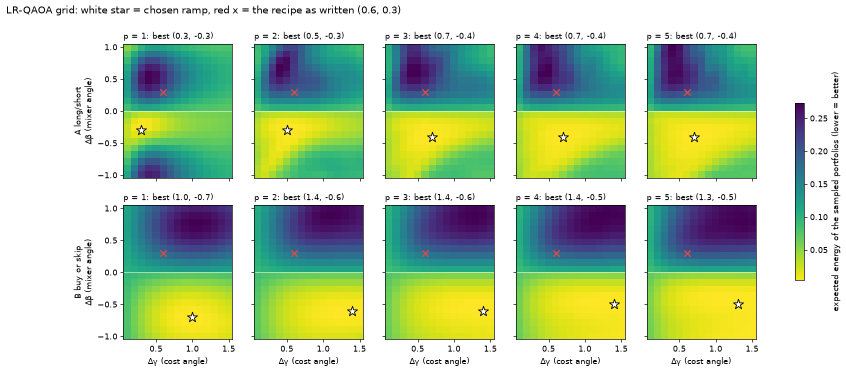

Text summary, A long/short: all chosen ramps have Δβ < 0; chosen (Δγ, Δβ) per p: p=1: (0.3, -0.3), p=2: (0.5, -0.3), p=3: (0.7, -0.4), p=4: (0.7, -0.4), p=5: (0.7, -0.4); none on the grid edge
Text summary, B buy or skip: all chosen ramps have Δβ < 0; chosen (Δγ, Δβ) per p: p=1: (1.0, -0.7), p=2: (1.4, -0.6), p=3: (1.4, -0.6), p=4: (1.4, -0.5), p=5: (1.3, -0.5); none on the grid edge


In [4]:
grid = META["tuning"]["lr_grid"]
dg, db = grid["dgamma"], grid["dbeta"]
fig, axes = plt.subplots(2, 5, figsize=(17, 6.4), sharex=True, sharey=True)
for row, m in enumerate(MODES):
    lr = R["models"][KEY[m]]["lr"]
    for col, p in enumerate(sorted(lr, key=int)):
        e = lr[p]
        ax = axes[row][col]
        values = np.array(e["expectation"])
        img = ax.imshow(values.T, origin="lower", aspect="auto", cmap="viridis_r",
                        extent=(dg[0] - 0.05, dg[-1] + 0.05, -1.05, 1.05))
        ax.scatter([e["best_dgamma"]], [e["best_dbeta"]], marker="*", s=160, color="white", edgecolor="black", zorder=3)
        ax.scatter([0.6], [0.3], marker="x", s=60, color="#e34948", zorder=3)
        ax.axhline(0, color="white", linewidth=0.6)
        ax.set_title(f"p = {p}: best ({e['best_dgamma']}, {e['best_dbeta']})", fontsize=9, loc="left")
        if row == 1:
            ax.set_xlabel("Δγ (cost angle)")
        if col == 0:
            ax.set_ylabel(f"{MODE_NAME[m]}\nΔβ (mixer angle)")
fig.colorbar(img, ax=axes.ravel().tolist(), shrink=0.6, label="expected energy of the sampled portfolios (lower = better)")
fig.suptitle("LR-QAOA grid: white star = chosen ramp, red x = the recipe as written (0.6, 0.3)", x=0.01, ha="left")
plt.show()
for m in MODES:
    lr = R["models"][KEY[m]]["lr"]
    edge = [p for p in lr if lr[p]["best_on_grid_edge"]]
    print(f"Text summary, {MODE_NAME[m]}: all chosen ramps have Δβ < 0; chosen (Δγ, Δβ) per p: "
          + ", ".join(f"p={p}: ({lr[p]['best_dgamma']}, {lr[p]['best_dbeta']})" for p in sorted(lr, key=int))
          + (f"; on the grid edge for p = {edge}" if edge else "; none on the grid edge"))

**How to read the grid charts.** X axis: Δγ, the size of the cost angles. Y axis: Δβ, the size of the mixer angles (negative below the white line). Colour: the expected energy of the portfolios the circuit samples; darker = lower = better. The white star is the chosen ramp, the red x is the published recipe (0.6, 0.3). **Conclusion:** the good region is entirely in the lower half (Δβ < 0); the recipe sits in the bright upper half, where the circuit samples worse-than-random portfolios.

*Numbers quoted here are from the saved run; the printed summaries recompute them from the results file.*

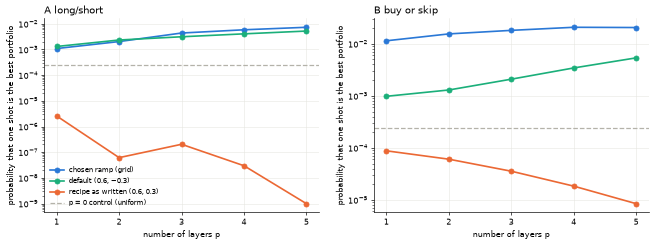

Text summary, A long/short: best ramp at p = 5: P(best portfolio) per shot 0.0073 = 30x the uniform control (0.00024); quality 0.950; chance to see the best portfolio at least once in 1000 shots 0.999. Recipe as written at the same p: 0.00000 per shot.
Text summary, B buy or skip: best ramp at p = 4: P(best portfolio) per shot 0.0207 = 85x the uniform control (0.00024); quality 0.973; chance to see the best portfolio at least once in 1000 shots 1.000. Recipe as written at the same p: 0.00002 per shot.


In [5]:
# how good is the chosen ramp as p grows, against the controls
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
for ax, m in zip(axes, MODES):
    lr = R["models"][KEY[m]]["lr"]
    ps = sorted(lr, key=int)
    x = [int(p) for p in ps]
    uniform = R["models"][KEY[m]]["baselines"]["p0_control_uniform"]["p_optimum_per_shot"]
    for key, color, label in (("best", BLUE, "chosen ramp (grid)"), ("sign_corrected_default", TEAL, "default (0.6, −0.3)"),
                              ("recipe_as_written", ORANGE, "recipe as written (0.6, 0.3)")):
        ax.plot(x, [lr[p][key]["p_optimum_per_shot"] for p in ps], marker="o", color=color, linewidth=2, label=label)
    ax.axhline(uniform, color=GREY, linestyle="--", linewidth=1.5, label="p = 0 control (uniform)")
    ax.set_yscale("log")
    ax.set_xticks(x)
    ax.set_xlabel("number of layers p")
    ax.set_ylabel("probability that one shot is the best portfolio")
    ax.set_title(MODE_NAME[m], loc="left")
    ax.grid(True, color="#e5e4df", linewidth=0.6)
    ax.spines[["top", "right"]].set_visible(False)
axes[0].legend(frameon=False, fontsize=8)
plt.show()
for m in MODES:
    lr = R["models"][KEY[m]]["lr"]
    u = R["models"][KEY[m]]["baselines"]["p0_control_uniform"]["p_optimum_per_shot"]
    best_p = max(lr, key=lambda p: lr[p]["best"]["p_optimum_per_shot"])
    b = lr[best_p]["best"]
    print(f"Text summary, {MODE_NAME[m]}: best ramp at p = {best_p}: P(best portfolio) per shot {b['p_optimum_per_shot']:.4f} "
          f"= {b['p_optimum_per_shot'] / u:.0f}x the uniform control ({u:.5f}); quality {b['quality']:.3f}; "
          f"chance to see the best portfolio at least once in {S['shots']} shots {b['p_optimum_in_shots']:.3f}. "
          f"Recipe as written at the same p: {lr[best_p]['recipe_as_written']['p_optimum_per_shot']:.5f} per shot.")

**How to read this chart.** X axis: layers p. Y axis (log scale): the chance that a single measured shot is exactly the best portfolio. Dashed grey = random guessing (the p = 0 control). **Conclusion:** the chosen ramp beats random guessing by a large factor and improves with p; the recipe as written stays at or below random.

*Numbers quoted here are from the saved run; the printed summaries recompute them from the results file.*

## 4. Standard QAOA with free angles: which optimiser?

Standard QAOA lets every layer have its own γ and β (2p numbers). They are tuned offline by five optimisers, each from the **same five starting points** (the default ramp, the grid-tuned ramp, three fixed-seed random points) and with the **same cap** of 200·p simulated circuits. SPSA is our own implementation. Every run is recorded, including the poor ones.

runs  failed  mean evaluations  quality mean  \
mode          p optimizer                                                   
A long/short  1 COBYLA          5       0           41.4000        0.8967   
                Nelder-Mead     5       0           71.6000        0.8967   
                Powell          5       0           81.4000        0.8442   
                L-BFGS-B        5       0           49.8000        0.8788   
                SPSA            5       0          199.0000        0.8840   
              2 COBYLA          5       0          177.4000        0.9168   
                Nelder-Mead     5       0          241.8000        0.9113   
                Powell          5       0          255.0000        0.8896   
                L-BFGS-B        5       0           85.0000        0.8935   
                SPSA            5       0          399.0000        0.9090   
              3 COBYLA          5       0          501.6000        0.8562   
                Nelder-Mead     5       0          527.0000        0.8767   
                Powell          5       0          310.6000        0.8377   
                L-BFGS-B        5       0          198.8000        0.8794   
                SPSA            5       0          599.0000        0.8665   
B buy or skip 1 COBYLA          5       0           35.6000        0.9551   
                Nelder-Mead     5       0           65.8000        0.9551   
                Powell          5       0           63.0000        0.9103   
                L-BFGS-B        5       0           22.8000        0.9551   
                SPSA            5       0          199.0000        0.9551   
              2 COBYLA          5       0          229.0000        0.9739   
                Nelder-Mead     5       0          285.4000        0.9726   
                Powell          5       0          273.4000        0.9651   
                L-BFGS-B        5       0          111.0000        0.9735   
                SPSA            5       0          399.0000        0.9689   
              3 COBYLA          5       0          600.0000        0.9742   
                Nelder-Mead     5       0          558.8000        0.9749   
                Powell          5       0          582.8000        0.9732   
                L-BFGS-B        5       0          303.8000        0.9793   
                SPSA            5       0          599.0000        0.9720   

                             quality worst  quality best  P(opt)/shot best  
mode          p optimizer                                                   
A long/short  1 COBYLA              0.8967        0.8967            0.0010  
                Nelder-Mead         0.8967        0.8967            0.0010  
                Powell              0.8087        0.8967            0.0010  
                L-BFGS-B            0.8072        0.8967            0.0010  
                SPSA                0.8336        0.8967            0.0010  
              2 COBYLA              0.9065        0.9194            0.0023  
                Nelder-Mead         0.9002        0.9194            0.0023  
                Powell              0.8156        0.9194            0.0023  
                L-BFGS-B            0.8028        0.9194            0.0023  
                SPSA                0.9054        0.9192            0.0023  
              3 COBYLA              0.8134        0.9346            0.0042  
                Nelder-Mead         0.8082        0.9346            0.0042  
                Powell              0.8122        0.9346            0.0042  
                L-BFGS-B            0.8113        0.9346            0.0042  
                SPSA                0.8095        0.9235            0.0049  
B buy or skip 1 COBYLA              0.9551        0.9551            0.0114  
                Nelder-Mead         0.9551        0.9551            0.0114  
                Powell              0.7313        0.9551            0.0114  
                L-BFGS-B

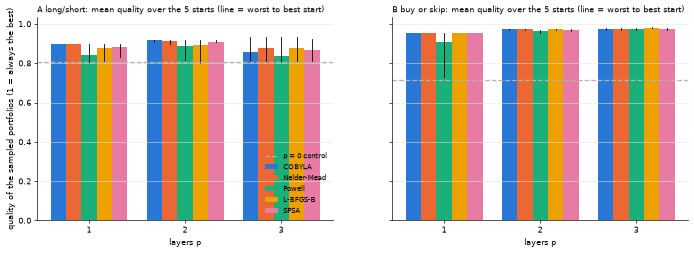

Text summary, A long/short: optimisers ranked by mean quality over all p and starts: Nelder-Mead 0.895, COBYLA 0.890, SPSA 0.887, L-BFGS-B 0.884, Powell 0.857. Best single run: p = 3, L-BFGS-B from 'lr_tuned' after 98 evaluations, quality 0.935, P(opt)/shot 0.0042.
Text summary, B buy or skip: optimisers ranked by mean quality over all p and starts: L-BFGS-B 0.969, COBYLA 0.968, Nelder-Mead 0.968, SPSA 0.965, Powell 0.950. Best single run: p = 3, L-BFGS-B from 'random_seed_5027' after 385 evaluations, quality 0.985, P(opt)/shot 0.0041.


In [6]:
rows = []
for m in MODES:
    by = R["models"][KEY[m]]["standard"]["by_optimizer"]
    for p, table in by.items():
        for optimizer, v in table.items():
            rows.append({"mode": MODE_NAME[m], "p": int(p), "optimizer": optimizer, "runs": v["runs"], "failed": v["failed"],
                         "mean evaluations": v["mean_evaluations"], "quality mean": v["quality_mean"],
                         "quality worst": v["quality_worst"], "quality best": v["quality_best"],
                         "P(opt)/shot best": v["p_optimum_per_shot_best"]})
opt_table = pd.DataFrame(rows).set_index(["mode", "p", "optimizer"])
with pd.option_context("display.max_rows", 100, "display.float_format", "{:.4f}".format):
    display(opt_table)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.4), sharey=True)
optimizers = list(META["tuning"]["optimizers"])
colors = dict(zip(optimizers, [BLUE, ORANGE, TEAL, YELLOW, PINK]))
for ax, m in zip(axes, MODES):
    by = R["models"][KEY[m]]["standard"]["by_optimizer"]
    ps = sorted(by, key=int)
    width = 0.8 / len(optimizers)
    for k, optimizer in enumerate(optimizers):
        xs = [int(p) + (k - (len(optimizers) - 1) / 2) * width for p in ps]
        means = [by[p][optimizer]["quality_mean"] for p in ps]
        ax.bar(xs, means, width=width, color=colors[optimizer], label=optimizer)
        for x, p in zip(xs, ps):
            ax.plot([x, x], [by[p][optimizer]["quality_worst"], by[p][optimizer]["quality_best"]], color="black", linewidth=1)
    u = R["models"][KEY[m]]["baselines"]["p0_control_uniform"]["quality"]
    ax.axhline(u, color=GREY, linestyle="--", linewidth=1.5, label="p = 0 control")
    ax.set_xticks([int(p) for p in ps])
    ax.set_xlabel("layers p")
    ax.set_title(f"{MODE_NAME[m]}: mean quality over the 5 starts (line = worst to best start)", loc="left", fontsize=10)
    ax.grid(True, axis="y", color="#e5e4df", linewidth=0.6)
    ax.spines[["top", "right"]].set_visible(False)
axes[0].set_ylabel("quality of the sampled portfolios (1 = always the best)")
axes[0].legend(frameon=False, fontsize=8, loc="lower right")
plt.show()
for m in MODES:
    by = R["models"][KEY[m]]["standard"]["by_optimizer"]
    best = R["models"][KEY[m]]["standard"]["best_by_p"]
    top_p = max(best, key=lambda p: best[p]["metrics"]["quality"])
    ranking = sorted(((np.mean([by[p][o]["quality_mean"] for p in by]), o) for o in optimizers), reverse=True)
    print(f"Text summary, {MODE_NAME[m]}: optimisers ranked by mean quality over all p and starts: "
          + ", ".join(f"{o} {q:.3f}" for q, o in ranking)
          + f". Best single run: p = {top_p}, {best[top_p]['optimizer']} from '{best[top_p]['start']}' after {best[top_p]['evaluations']} "
            f"evaluations, quality {best[top_p]['metrics']['quality']:.3f}, P(opt)/shot {best[top_p]['metrics']['p_optimum_per_shot']:.4f}.")

**How to read this chart.** X axis: layers p. Y axis: the quality of the portfolios the tuned circuit samples (1 = always the best, 0 = always the worst). One bar per optimiser = the average over the five starting points; the black line runs from the worst start to the best. Dashed grey = random guessing. **Conclusion:** the starting point matters more than the optimiser: starting from the tuned ramp, all optimisers reach about the same quality, while random starts often get stuck. More layers help a little.

*Numbers quoted here are from the saved run; the printed summaries recompute them from the results file.*

## 5. Baselines on the same model: p = 0 control, random, greedy, simulated annealing, exact

Same conventions as Task 3. 'Hit rate per try' = share of samples (random) or restarts (greedy, annealing) that reach the exact optimum. For QAOA the comparable number is P(optimum) per shot.

In [7]:
rows = []
for m in MODES:
    b = R["models"][KEY[m]]["baselines"]
    rows.append({"mode": MODE_NAME[m], "method": "exact (4,096 states)", "P(optimum) per try": 1.0, "tries": 4096, "note": f"E_min {b['exact']['e_min']:+.5f}, {b['exact']['n_optimal']} optimum"})
    rows.append({"mode": MODE_NAME[m], "method": "p = 0 control (uniform shots)", "P(optimum) per try": b["p0_control_uniform"]["p_optimum_per_shot"], "tries": S["shots"], "note": f"quality {b['p0_control_uniform']['quality']:.3f}"})
    for name, v in b["classical"].items():
        rows.append({"mode": MODE_NAME[m], "method": name, "P(optimum) per try": v["hit_rate_per_try"], "tries": v["tries_per_seed"],
                     "note": f"hit at least once in {v['tries_per_seed']} tries: {v['p_hit_at_least_once']:.3f}"})
with pd.option_context("display.float_format", "{:.5f}".format, "display.max_colwidth", 60):
    display(pd.DataFrame(rows).set_index(["mode", "method"]))
print("Text summary: random guessing finds the best portfolio in about 1 try in 4,000; greedy and annealing in most tries. "
      "QAOA's P(optimum) per shot (next section) sits between the two.")

P(optimum) per try  tries  \
mode          method                                                     
A long/short  exact (4,096 states)                      1.00000   4096   
              p = 0 control (uniform shots)             0.00024   1000   
              random                                    0.00000   1000   
              greedy                                    0.06667     30   
              annealing                                 0.25556     30   
B buy or skip exact (4,096 states)                      1.00000   4096   
              p = 0 control (uniform shots)             0.00024   1000   
              random                                    0.00000   1000   
              greedy                                    1.00000     30   
              annealing                                 1.00000     30   

                                                                               note  
mode          method                                                                 
A long/short  exact (4,096 states)                        E_min +0.01535, 1 optimum  
              p = 0 control (uniform shots)                           quality 0.807  
              random                         hit at least once in 1000 tries: 0.000  
              greedy                           hit at least once in 30 tries: 0.874  
              annealing                        hit at least once in 30 tries: 1.000  
B buy or skip exact (4,096 states)                        E_min -0.00433, 1 optimum  
              p = 0 control (uniform shots)                           quality 0.714  
              random                         hit at least once in 1000 tries: 0.000  
              greedy                           hit at least once in 30 tries: 1.000  
              annealing                        hit at least once in 30 tries: 1.000

Text summary: random guessing finds the best portfolio in about 1 try in 4,000; greedy and annealing in most tries. QAOA's P(optimum) per shot (next section) sits between the two.


## 6. The ladder: how every method compares on the same measure

For every method, the probability that one shot (or one classical try) is the best portfolio, and the quality of the sampled distribution. QAOA numbers are exact statevector probabilities; the 'in 1000 shots' column is the chance of seeing the best portfolio at least once.

A long/short


,quality,P(optimum) per shot,within 1 % per shot,P(seen in 1000 shots),expected best quality in shots,tuning evaluations
method,,,,,,
p = 0 control (uniform),0.8071,0.0002,0.0024,0.2166,0.9936,NaN
LR-QAOA p=1,0.8955,0.0011,0.0102,0.6631,0.9979,NaN
LR-QAOA p=2,0.9159,0.0020,0.0175,0.8693,0.9992,NaN
LR-QAOA p=3,0.9315,0.0044,0.0336,0.9874,0.9999,NaN
LR-QAOA p=4,0.9431,0.0058,0.0425,0.9972,1.0000,NaN
LR-QAOA p=5,0.9500,0.0073,0.0513,0.9994,1.0000,NaN
standard QAOA p=1,0.8967,0.0010,0.0099,0.6496,0.9978,24.0000
standard QAOA p=2,0.9194,0.0023,0.0196,0.8993,0.9994,65.0000
standard QAOA p=3,0.9346,0.0042,0.0330,0.9858,0.9999,98.0000


B buy or skip


,quality,P(optimum) per shot,within 1 % per shot,P(seen in 1000 shots),expected best quality in shots,tuning evaluations
method,,,,,,
p = 0 control (uniform),0.7140,0.0002,0.0029,0.2166,0.9967,NaN
LR-QAOA p=1,0.9548,0.0114,0.1059,1.0000,1.0000,NaN
LR-QAOA p=2,0.9686,0.0155,0.1363,1.0000,1.0000,NaN
LR-QAOA p=3,0.9717,0.0181,0.1487,1.0000,1.0000,NaN
LR-QAOA p=4,0.9730,0.0207,0.1643,1.0000,1.0000,NaN
LR-QAOA p=5,0.9724,0.0205,0.1612,1.0000,1.0000,NaN
standard QAOA p=1,0.9551,0.0114,0.1070,1.0000,1.0000,83.0000
standard QAOA p=2,0.9764,0.0122,0.1367,1.0000,1.0000,70.0000
standard QAOA p=3,0.9847,0.0041,0.1228,0.9841,1.0000,385.0000


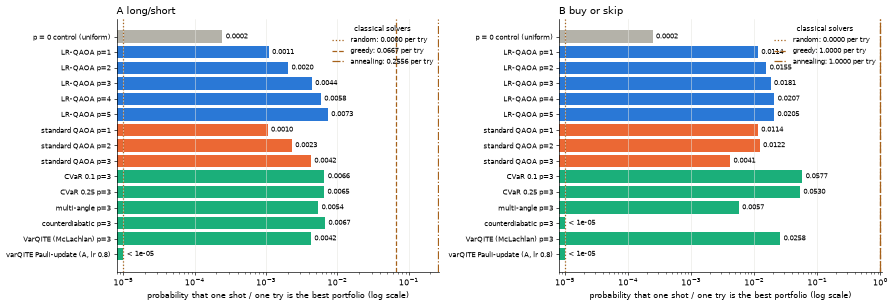

Text summary, A long/short: best quantum variant is 'LR-QAOA p=5' with P(best portfolio) per shot 0.0073 = 30x random guessing; greedy reaches it in 0.07 of its tries.
Text summary, B buy or skip: best quantum variant is 'CVaR 0.1 p=3' with P(best portfolio) per shot 0.0577 = 236x random guessing; greedy reaches it in 1.00 of its tries.


In [8]:
def best_extra(extra):
    if extra.get("status") != "completed" or "summary" not in extra or not extra["summary"]["best_by_p"]:
        return None
    best_by_p = extra["summary"]["best_by_p"]
    p = max(best_by_p, key=lambda q: -best_by_p[q]["objective_value"])
    return p, best_by_p[p]["metrics"]

ladder_rows = {}
for m in MODES:
    r, rows = R["models"][KEY[m]], []
    b = r["baselines"]
    rows.append(("p = 0 control (uniform)", b["p0_control_uniform"], None))
    for p in sorted(r["lr"], key=int):
        rows.append((f"LR-QAOA p={p}", r["lr"][p]["best"], None))
    for p in sorted(r["standard"]["best_by_p"], key=int):
        rows.append((f"standard QAOA p={p}", r["standard"]["best_by_p"][p]["metrics"], r["standard"]["best_by_p"][p]["evaluations"]))
    for name, label in (("cvar_0.1", "CVaR 0.1"), ("cvar_0.25", "CVaR 0.25"), ("multi_angle", "multi-angle"), ("dc", "counterdiabatic"), ("varqite", "VarQITE (McLachlan)")):
        picked = best_extra(R["extras"][KEY[m]].get(name, {}))
        if picked:
            rows.append((f"{label} p={picked[0]}", picked[1], None))
    v = R["extras"][KEY[m]].get("varqite_pauli", {})
    if v.get("status") == "completed":
        rows.append((f"varQITE Pauli-update ({v['best']['kind']}, lr {v['best']['lr']})", v["best"]["metrics"], v["best"]["evaluations"]))
    ladder_rows[m] = rows
    table = pd.DataFrame([{"method": name, "quality": met["quality"], "P(optimum) per shot": met["p_optimum_per_shot"],
                           "within 1 % per shot": met.get("p_within_1pct"), f"P(seen in {S['shots']} shots)": met["p_optimum_in_shots"],
                           "expected best quality in shots": met.get("expected_best_quality"), "tuning evaluations": ev}
                          for name, met, ev in rows]).set_index("method")
    print(MODE_NAME[m])
    with pd.option_context("display.float_format", "{:.4f}".format):
        display(table)

fig, axes = plt.subplots(1, 2, figsize=(15, 5.2))
for ax, m in zip(axes, MODES):
    rows = ladder_rows[m]
    names = [n for n, _, _ in rows]
    floor = 1e-5
    values = [met["p_optimum_per_shot"] for _, met, _ in rows]
    colors = [GREY if "control" in n else BLUE if n.startswith("LR") else ORANGE if n.startswith("standard") else TEAL for n in names]
    y = np.arange(len(rows))
    ax.barh(y, [max(v, floor) for v in values], color=colors)
    for yy, v in zip(y, values):
        ax.annotate(f"{v:.4f}" if v >= floor else f"< {floor:g}", (max(v, floor), yy), xytext=(4, 0), textcoords="offset points", va="center", fontsize=8)
    handles = []
    for (name, v), style in zip(R["models"][KEY[m]]["baselines"]["classical"].items(), (":", "--", "-.")):
        rate = max(v["hit_rate_per_try"], floor)
        ax.axvline(rate, color=BROWN, linestyle=style, linewidth=1.5)
        handles.append(plt.Line2D([], [], color=BROWN, linestyle=style, label=f"{name}: {v['hit_rate_per_try']:.4f} per try"))
    ax.legend(handles=handles, frameon=False, fontsize=8, loc="upper right", title="classical solvers", title_fontsize=8)
    ax.set_xlim(left=floor * 0.8)
    ax.set_yticks(y, names, fontsize=8)
    ax.set_xscale("log")
    ax.set_xlabel("probability that one shot / one try is the best portfolio (log scale)")
    ax.set_title(MODE_NAME[m], loc="left")
    ax.invert_yaxis()
    ax.grid(True, axis="x", color="#e5e4df", linewidth=0.6)
    ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
plt.show()
for m in MODES:
    rows = ladder_rows[m]
    u = rows[0][1]["p_optimum_per_shot"]
    top = max(rows[1:], key=lambda r: r[1]["p_optimum_per_shot"])
    print(f"Text summary, {MODE_NAME[m]}: best quantum variant is '{top[0]}' with P(best portfolio) per shot {top[1]['p_optimum_per_shot']:.4f} "
          f"= {top[1]['p_optimum_per_shot'] / u:.0f}x random guessing; greedy reaches it in "
          f"{R['models'][KEY[m]]['baselines']['classical']['greedy']['hit_rate_per_try']:.2f} of its tries.")

**How to read this chart.** Y axis: the methods. X axis (log scale): the chance that one measured shot is exactly the best portfolio; grey = random guessing, blue = linear-ramp QAOA, orange = free-angle QAOA, teal = the extra variants. Dotted brown lines = the classical solvers' hit rate per try. **Conclusion:** every tuned quantum variant beats random guessing by a factor of 5 to 50, and none comes close to greedy or annealing, which find the best portfolio in most tries. On this small problem the quantum sampler is a demonstrably better-than-random sampler, not a better optimiser.

*Numbers quoted here are from the saved run; the printed summaries recompute them from the results file.*

## 7. The balance switch in the circuit: penalty vs post-selection vs XY mixer

Three ways to get 'equal buys and sells' from a quantum circuit: (1) put the penalty into the model (Task 3's verified λ), (2) run the unconstrained circuit and keep only the balanced shots, (3) a mixer that never leaves the balanced states (Dicke start + XX+YY gates on a ring). Measured: the share of balanced shots and the chance that a shot is the best **balanced** portfolio. The penalty coupling is many times larger than the portfolio couplings, so the circuit mostly learns the constraint rather than the portfolio.

A long/short: penalty coupling 2λ = 0.1780 is 12x the largest objective term 0.0151
B buy or skip: penalty coupling 2λ = 0.1445 is 5x the largest objective term 0.0301


balanced share  \
mode          p method                                         
A long/short  0 uniform shots, post-selected          0.2256   
              1 penalty lr                            0.5164   
                postselect lr                         0.3089   
                penalty standard                      0.5784   
                postselect standard                   0.3168   
              2 penalty lr                            0.5397   
                postselect lr                         0.3026   
                penalty standard                      0.9718   
                postselect standard                   0.3048   
              1 XY mixer (Dicke start)                1.0000   
              2 XY mixer (Dicke start)                1.0000   
B buy or skip 0 uniform shots, post-selected          0.2256   
              1 penalty lr                            0.5309   
                postselect lr                         0.0313   
                penalty standard                      0.5780   
                postselect standard                   0.0329   
              2 penalty lr                            0.5536   
                postselect lr                         0.0128   
                penalty standard                      0.9683   
                postselect standard                   0.0065   
              1 XY mixer (Dicke start)                1.0000   
              2 XY mixer (Dicke start)                1.0000   

                                              P(best balanced)/shot  \
mode          p method                                                
A long/short  0 uniform shots, post-selected                 0.0002   
              1 penalty lr                                   0.0006   
                postselect lr                                0.0011   
                penalty standard                             0.0006   
                postselect standard                          0.0010   
              2 penalty lr                                   0.0006   
                postselect lr                                0.0018   
                penalty standard                             0.0011   
                postselect standard                          0.0019   
              1 XY mixer (Dicke start)                       0.0071   
              2 XY mixer (Dicke start)                       0.0192   
B buy or skip 0 uniform shots, post-selected                 0.0002   
              1 penalty lr                                   0.0006   
                postselect lr                                0.0007   
                penalty standard                             0.0006   
                postselect standard                          0.0007   
              2 penalty lr                                   0.0006   
                postselect lr                                0.0009   
                penalty standard                             0.0011   
                postselect standard                          0.0002   
              1 XY mixer (Dicke start)                       0.0008   
              2 XY mixer (Dicke start)                       0.0068   

                                              quality of balanced shots  
mode          p method                                                   
A long/short  0 uniform shots, post-selected                     0.6391  
              1 penalty lr                                       0.6414  
                postselect lr                                    0.7603  
                penalty standard                                 0.6416  
                postselect standard                              0.7567  
              2 penalty lr                                       0.6420  
                postselect lr                                    0.8002  
                penalty standard                                 0.6419  
                postselect standard                             

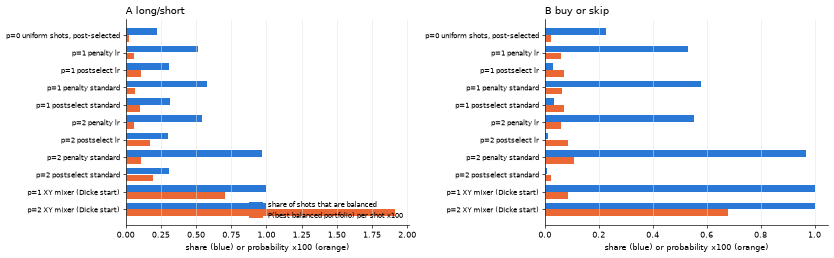

Text summary, A long/short: highest P(best balanced portfolio) per shot: XY mixer (Dicke start) at p = 2 (0.0192); the penalty raises the balanced share but not the chance of the best portfolio.
Text summary, B buy or skip: highest P(best balanced portfolio) per shot: XY mixer (Dicke start) at p = 2 (0.0068); the penalty raises the balanced share but not the chance of the best portfolio.


In [9]:
rows = []
for m in MODES:
    b = R["balance"][m]
    u = b["postselect_uniform_p0"]
    rows.append({"mode": MODE_NAME[m], "p": 0, "method": "uniform shots, post-selected", "balanced share": u["feasible_share"], "P(best balanced)/shot": u["p_optimum_per_shot"], "quality of balanced shots": u["quality"]})
    for p, e in b["by_p"].items():
        for name, v in e.items():
            rows.append({"mode": MODE_NAME[m], "p": int(p), "method": name.replace("_", " "), "balanced share": v["feasible_share"], "P(best balanced)/shot": v["p_optimum_per_shot"], "quality of balanced shots": v["quality"]})
    xy = R["extras"].get("xy_mixer", {})
    if xy.get("status") == "completed":
        for p, best in xy["modes"][m]["summary"]["best_by_p"].items():
            met = best["metrics"]
            rows.append({"mode": MODE_NAME[m], "p": int(p), "method": "XY mixer (Dicke start)", "balanced share": met["feasible_share"], "P(best balanced)/shot": met["p_optimum_per_shot"], "quality of balanced shots": met["quality"]})
    print(f"{MODE_NAME[m]}: penalty coupling 2λ = {b['penalty_coupling']:.4f} is {b['penalty_to_objective_ratio']:.0f}x the largest objective term {b['largest_objective_term']:.4f}")
bal = pd.DataFrame(rows).set_index(["mode", "p", "method"])
with pd.option_context("display.float_format", "{:.4f}".format):
    display(bal)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.4))
for ax, m in zip(axes, MODES):
    sub = bal.loc[MODE_NAME[m]].reset_index()
    labels = [f"p={p} {meth}" for p, meth in zip(sub["p"], sub["method"])]
    y = np.arange(len(sub))
    ax.barh(y - 0.2, sub["balanced share"], height=0.38, color=BLUE, label="share of shots that are balanced")
    ax.barh(y + 0.2, sub["P(best balanced)/shot"] * 100, height=0.38, color=ORANGE, label="P(best balanced portfolio) per shot x100")
    ax.set_yticks(y, labels, fontsize=8)
    ax.invert_yaxis()
    ax.set_xlabel("share (blue) or probability x100 (orange)")
    ax.set_title(MODE_NAME[m], loc="left")
    ax.grid(True, axis="x", color="#e5e4df", linewidth=0.6)
    ax.spines[["top", "right"]].set_visible(False)
axes[0].legend(frameon=False, fontsize=8, loc="lower right")
fig.tight_layout()
plt.show()
for m in MODES:
    sub = bal.loc[MODE_NAME[m]]
    best = sub["P(best balanced)/shot"].idxmax()
    print(f"Text summary, {MODE_NAME[m]}: highest P(best balanced portfolio) per shot: {best[1]} at p = {best[0]} "
          f"({sub.loc[best, 'P(best balanced)/shot']:.4f}); the penalty raises the balanced share but not the chance of the best portfolio.")

**How to read this chart.** Y axis: the balance methods per number of layers. Blue bar: how many of the shots are balanced (1.0 = all of them). Orange bar: the chance per shot of the best balanced portfolio, ×100. **Conclusion:** the XY mixer keeps every shot balanced by construction and gives the highest chance of the best balanced portfolio; the penalty makes more shots balanced than post-selection but does not improve their quality, because the penalty term dominates the circuit. Post-selection of the unconstrained circuit is the cheapest option and is what the next task will use at 29 qubits (the XY mixer needs a Dicke-state preparation whose gate cost is not implemented efficiently here).

*Numbers quoted here are from the saved run; the printed summaries recompute them from the results file.*

## 8. Gate counts: 12 and 29 qubits, all-to-all vs a heavy-hex grid

The 29-qubit circuits are **built and counted only, never simulated**. Their angles come from the ramp tuned at 12 assets for the same mode and p (transfer rule); they are not tuned for 29 assets. Routing on a heavy-hex grid (a superconducting layout) adds SWAP gates; on a trapped-ion machine every pair is connected, so no SWAPs are needed and `rzz` is one native gate on IonQ Forte.

pair terms  two-qubit gates per layer (all-to-all)  \
qubits mode                                                                
12     A long/short           66                                      66   
       B buy or skip          66                                      66   
29     A long/short          244                                     244   
       B buy or skip         244                                     244   

                      two-qubit depth (all-to-all)  \
qubits mode                                          
12     A long/short                             15   
       B buy or skip                            15   
29     A long/short                             29   
       B buy or skip                            29   

                      two-qubit gates on heavy-hex (19 qubits), median  \
qubits mode                                                              
12     A long/short                                              285.0   
       B buy or skip                                             285.0   
29     A long/short                                                NaN   
       B buy or skip                                               NaN   

                     heavy-hex min-max  \
qubits mode                              
12     A long/short            276-288   
       B buy or skip           276-288   
29     A long/short          1510-1597   
       B buy or skip         1510-1597   

                                                                 angles  \
qubits mode                                                               
12     A long/short                                         tuned at 12   
       B buy or skip                                        tuned at 12   
29     A long/short   linear ramp tuned at n = 12 (same mode), NOT t...   
       B buy or skip  linear ramp tuned at n = 12 (same mode), NOT t...   

                      two-qubit gates on heavy-hex (57 qubits), median  
qubits mode                                                             
12     A long/short                                                NaN  
       B buy or skip                                               NaN  
29     A long/short                                             1576.0  
       B buy or skip                                            1576.0

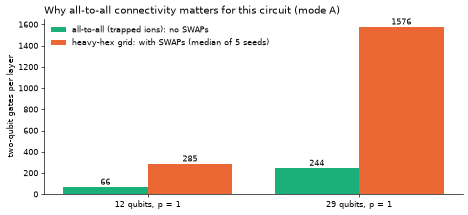

Text summary: one layer needs 66 two-qubit gates at 12 qubits and 244 at 29 on an all-to-all machine; routed on a heavy-hex grid the same layer needs 285 and 1576 (4.3x and 6.5x more). Measured with Qiskit's transpiler, optimization level 1.


In [10]:
rows = []
for size, block in (("12", R["circuits"]["n12"]), ("29", R["circuits"]["large"])):
    for m, c in block.items():
        one = c["by_p"]["1"]
        r = c["routing_p1"]
        rows.append({"qubits": int(size), "mode": MODE_NAME[m], "pair terms": one["two_qubit_gates"],
                     "two-qubit gates per layer (all-to-all)": r["all_to_all_two_qubit_gates"], "two-qubit depth (all-to-all)": r["all_to_all_two_qubit_depth"],
                     f"two-qubit gates on heavy-hex ({r['heavy_hex_qubits']} qubits), median": r["heavy_hex_two_qubit_gates"]["median"],
                     "heavy-hex min-max": f"{r['heavy_hex_two_qubit_gates']['min']}-{r['heavy_hex_two_qubit_gates']['max']}",
                     "angles": "tuned at 12" if size == "12" else c["angles_from"]})
display(pd.DataFrame(rows).set_index(["qubits", "mode"]))

fig, ax = plt.subplots(figsize=(9, 3.8))
labels, flat, hex_ = [], [], []
for size, block in (("12", R["circuits"]["n12"]), ("29", R["circuits"]["large"])):
    c = block["long_short"]["routing_p1"]
    labels.append(f"{size} qubits, p = 1"); flat.append(c["all_to_all_two_qubit_gates"]); hex_.append(c["heavy_hex_two_qubit_gates"]["median"])
x = np.arange(len(labels))
ax.bar(x - 0.2, flat, width=0.4, color=TEAL, label="all-to-all (trapped ions): no SWAPs")
ax.bar(x + 0.2, hex_, width=0.4, color=ORANGE, label="heavy-hex grid: with SWAPs (median of 5 seeds)")
for xx, a, b in zip(x, flat, hex_):
    ax.annotate(str(a), (xx - 0.2, a), xytext=(0, 3), textcoords="offset points", ha="center", fontsize=9)
    ax.annotate(str(b), (xx + 0.2, b), xytext=(0, 3), textcoords="offset points", ha="center", fontsize=9)
ax.set_xticks(x, labels)
ax.set_ylabel("two-qubit gates per layer")
ax.set_title("Why all-to-all connectivity matters for this circuit (mode A)", loc="left")
ax.legend(frameon=False, fontsize=9)
ax.spines[["top", "right"]].set_visible(False)
plt.show()
c12, c29 = R["circuits"]["n12"]["long_short"]["routing_p1"], R["circuits"]["large"]["long_short"]["routing_p1"]
print(f"Text summary: one layer needs {c12['all_to_all_two_qubit_gates']} two-qubit gates at 12 qubits and {c29['all_to_all_two_qubit_gates']} at 29 "
      f"on an all-to-all machine; routed on a heavy-hex grid the same layer needs {c12['heavy_hex_two_qubit_gates']['median']} and "
      f"{c29['heavy_hex_two_qubit_gates']['median']} ({c12['heavy_hex_two_qubit_gates']['median'] / c12['all_to_all_two_qubit_gates']:.1f}x and "
      f"{c29['heavy_hex_two_qubit_gates']['median'] / c29['all_to_all_two_qubit_gates']:.1f}x more). Measured with Qiskit's transpiler, optimization level 1.")

## 9. Does the 12-asset ramp transfer to more assets?

The only way to run 29 qubits is to transfer angles, so the transfer is measured where the statevector is still feasible: at 16 assets (where a fresh grid is also run for comparison) and at 20 assets, dense and thinned to 60 % of the links like the 29-asset model.

rule: for a larger size use the linear ramp (dgamma, dbeta) tuned at n = 12 for the same mode and p, with the larger model's own scale; it is not re-tuned


quality  P(opt)/shot  \
n  links kept mode          p angles                                       
16 1.0000     A long/short  1 transferred from 12    0.8887       0.0001   
                            2 transferred from 12    0.9047       0.0001   
                            3 transferred from 12    0.9221       0.0003   
                            1 own grid (0.4, -0.3)   0.8904       0.0001   
                            2 own grid (0.8, -0.3)   0.9099       0.0002   
                            3 own grid (1.0, -0.4)   0.9259       0.0005   
              B buy or skip 1 transferred from 12    0.9493       0.0013   
                            2 transferred from 12    0.9604       0.0019   
                            3 transferred from 12    0.9633       0.0022   
                            1 own grid (1.0, -0.7)   0.9493       0.0013   
                            2 own grid (1.3, -0.6)   0.9605       0.0018   
                            3 own grid (1.4, -0.6)   0.9633       0.0022   
20 1.0000     A long/short  1 transferred from 12    0.9055       0.0000   
                            2 transferred from 12    0.9193       0.0000   
                            3 transferred from 12    0.9367       0.0000   
              B buy or skip 1 transferred from 12    0.9586       0.0006   
                            2 transferred from 12    0.9678       0.0010   
                            3 transferred from 12    0.9692       0.0011   
   0.6000     A long/short  1 transferred from 12    0.8645       0.0000   
                            2 transferred from 12    0.8819       0.0000   
                            3 transferred from 12    0.8995       0.0001   
              B buy or skip 1 transferred from 12    0.9505       0.0007   
                            2 transferred from 12    0.9630       0.0012   
                            3 transferred from 12    0.9660       0.0013   

                                                    x uniform  \
n  links kept mode          p angles                            
16 1.0000     A long/short  1 transferred from 12      4.1475   
                            2 transferred from 12      8.0578   
                            3 transferred from 12     19.9105   
                            1 own grid (0.4, -0.3)     5.1528   
                            2 own grid (0.8, -0.3)    13.2779   
                            3 own grid (1.0, -0.4)    35.5574   
              B buy or skip 1 transferred from 12     86.6108   
                            2 transferred from 12    125.5473   
                            3 transferred from 12    143.8163   
                            1 own grid (1.0, -0.7)    86.6108   
                            2 own grid (1.3, -0.6)   115.1927   
                            3 own grid (1.4, -0.6)   143.8163   
20 1.0000     A long/short  1 transferred from 12      6.0831   
                            2 transferred from 12     13.4448   
                            3 transferred from 12     48.0965   
              B buy or skip 1 transferred from 12    673.6535   
                            2 transferred from 12   1021.9680   
                            3 transferred from 12   1116.9954   
   0.6000     A long/short  1 transferred from 12     10.1336   
                            2 transferred from 12     33.1736   
                            3 transferred from 12    154.2590   
              B buy or skip 1 transferred from 12    769.5792   
                            2 transferred from 12   1214.0312   
                            3 transferred from 12   1409.5863   

                                                    dense re-scored quality  
n  links kept mode          p angles                                         
16 1.0000     A long/short  1 transferred from 12                       NaN  
                            2 transferred from 12                       NaN  
                            3 transferred from 12                       

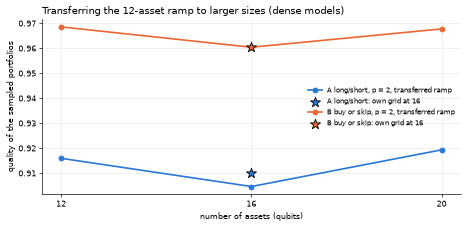

Text summary, A long/short: quality with the transferred ramp (p = 2): 12 assets 0.916, 16 assets 0.905 (own grid 0.910), 20 assets 0.919; P(opt)/shot at 20 assets is 13x uniform.
Text summary, B buy or skip: quality with the transferred ramp (p = 2): 12 assets 0.969, 16 assets 0.960 (own grid 0.960), 20 assets 0.968; P(opt)/shot at 20 assets is 1022x uniform.


In [11]:
t = R["transfer"]
if t.get("status") != "completed":
    print("transfer check:", t)
else:
    print("rule:", t["rule"])
    rows = []
    for label in ("tuned_size", "larger_size_dense", "larger_size_thinned"):
        e = t[label]
        for m, row in e["modes"].items():
            u = row["uniform_p0"]["p_optimum_per_shot"]
            for p, met in row["transferred"].items():
                rows.append({"n": e["n"], "links kept": e["keep_fraction"], "mode": MODE_NAME[m], "p": int(p), "angles": "transferred from 12",
                             "quality": met["quality"], "P(opt)/shot": met["p_optimum_per_shot"], "x uniform": met["p_optimum_per_shot"] / u if u > 0 else np.nan,
                             "dense re-scored quality": row.get("transferred_dense", {}).get(p, {}).get("quality")})
            for p, met in row.get("own_grid", {}).items():
                rows.append({"n": e["n"], "links kept": e["keep_fraction"], "mode": MODE_NAME[m], "p": int(p), "angles": f"own grid ({met['best_dgamma']}, {met['best_dbeta']})",
                             "quality": met["quality"], "P(opt)/shot": met["p_optimum_per_shot"], "x uniform": met["p_optimum_per_shot"] / u if u > 0 else np.nan,
                             "dense re-scored quality": None})
    tr = pd.DataFrame(rows).set_index(["n", "links kept", "mode", "p", "angles"])
    with pd.option_context("display.float_format", "{:.4f}".format, "display.max_rows", 100):
        display(tr)
    fig, ax = plt.subplots(figsize=(9, 3.8))
    for m, color in zip(MODES, (BLUE, ORANGE)):
        xs, ys = [], []
        for label, n in (("tuned_size", 16), ("larger_size_dense", 20)):
            row = t[label]["modes"][m]
            xs.append(n); ys.append(row["transferred"]["2"]["quality"])
        ys = [R["models"][KEY[m]]["lr"]["2"]["best"]["quality"]] + ys
        ax.plot([12] + xs, ys, marker="o", color=color, linewidth=2, label=f"{MODE_NAME[m]}, p = 2, transferred ramp")
        own = t["tuned_size"]["modes"][m]["own_grid"]["2"]["quality"]
        ax.scatter([16], [own], marker="*", s=160, color=color, edgecolor="black", zorder=3, label=f"{MODE_NAME[m]}: own grid at 16")
    ax.set_xticks([12, 16, 20])
    ax.set_xlabel("number of assets (qubits)")
    ax.set_ylabel("quality of the sampled portfolios")
    ax.set_title("Transferring the 12-asset ramp to larger sizes (dense models)", loc="left")
    ax.grid(True, color="#e5e4df", linewidth=0.6)
    ax.spines[["top", "right"]].set_visible(False)
    ax.legend(frameon=False, fontsize=8)
    plt.show()
    for m in MODES:
        a, b = t["tuned_size"]["modes"][m], t["larger_size_dense"]["modes"][m]
        print(f"Text summary, {MODE_NAME[m]}: quality with the transferred ramp (p = 2): 12 assets {R['models'][KEY[m]]['lr']['2']['best']['quality']:.3f}, "
              f"16 assets {a['transferred']['2']['quality']:.3f} (own grid {a['own_grid']['2']['quality']:.3f}), 20 assets {b['transferred']['2']['quality']:.3f}; "
              f"P(opt)/shot at 20 assets is {b['transferred']['2']['p_optimum_per_shot'] / b['uniform_p0']['p_optimum_per_shot']:.0f}x uniform.")

**How to read this chart.** X axis: number of assets. Y axis: quality of the sampled portfolios with the ramp tuned at 12 assets. Stars: what a fresh grid search finds at 16 assets. **Conclusion:** the transferred ramp keeps its quality as the size grows and is close to what re-tuning would give, which supports using it (untuned) at 29 qubits. The chance of the exact best portfolio per shot shrinks with size for every method, because there are 2^n portfolios.

*Numbers quoted here are from the saved run; the printed summaries recompute them from the results file.*

## 10. The extras that were tried

Each extra used the **same optimisers, starts and evaluation cap** as the standard runs it is compared with, and all runs are kept, including the ones that did not help.
- **CVaR objective** (α = 0.1, 0.25): tune on the mean of the best α share of the distribution.
- **Multi-angle** (3p numbers): separate angle for the links and for the single-asset terms.
- **Counterdiabatic / DC-QAOA** (3p numbers): an extra `ry` rotation on every qubit after the mixer (first-order counterdiabatic term; related prior art: IonQ/Kipu portfolio paper, arXiv 2602.23976).
- **VarQITE (McLachlan)**: imaginary-time evolution of the QAOA angles, offline, as another way to train them.
- **varQITE with the Pauli-term update rule** (IonQ + ORNL, arXiv 2404.16135; implemented from the method description, no code reused): a different ansatz, one parameter per link, trained offline; the final circuit would be sampled on the backend.
- **Exact imaginary-time evolution** of the uniform state: for a diagonal cost this is a *classical* Boltzmann distribution p(z) ∝ exp(−2τE(z)); shown as a reference curve only.
- **Deferred:** warm start, variational real-time evolution, recursive QAOA (see the printed note).

In [12]:
rows = []
for m in MODES:
    ex = R["extras"][KEY[m]]
    for name in ("cvar_0.1", "cvar_0.25", "multi_angle", "dc", "varqite"):
        e = ex.get(name, {})
        if e.get("status") != "completed":
            rows.append({"mode": MODE_NAME[m], "extra": name, "p": "", "status": e.get("status", "missing"), "error": e.get("error")})
            continue
        ref = e.get("standard_same_budget", e.get("standard_all_optimizers", {}))
        for p, best in e["summary"]["best_by_p"].items():
            r = ref.get("best_by_p", {}).get(p)
            rows.append({"mode": MODE_NAME[m], "extra": name, "p": int(p), "status": "completed", "quality": best["metrics"]["quality"],
                         "P(opt)/shot": best["metrics"]["p_optimum_per_shot"], "evaluations": best["evaluations"],
                         "standard quality (same budget)": r["metrics"]["quality"] if r else None,
                         "standard P(opt)/shot": r["metrics"]["p_optimum_per_shot"] if r else None,
                         "runs": e["summary"]["by_optimizer"][p] and sum(v["runs"] for v in e["summary"]["by_optimizer"][p].values()),
                         "failed runs": sum(v["failed"] for v in e["summary"]["by_optimizer"][p].values())})
extras_table = pd.DataFrame(rows).set_index(["mode", "extra", "p"])
with pd.option_context("display.float_format", "{:.4f}".format, "display.max_rows", 100):
    display(extras_table)
print("deferred:", json.dumps(R["extras"]["deferred"], indent=1))
for m in MODES:
    sub = extras_table.loc[MODE_NAME[m]]
    sub = sub[sub["status"] == "completed"]
    gains = (sub["P(opt)/shot"] - sub["standard P(opt)/shot"]).dropna()
    better = gains[gains > 1e-6]
    label = lambda idx: f"{idx[0]} p={int(idx[1])}"
    print(f"Text summary, {MODE_NAME[m]}: {len(better)} of {len(gains)} extra configurations raised P(opt)/shot over standard QAOA at the same "
          f"budget; largest gain {gains.max():+.4f} ({label(gains.idxmax())}), largest loss {gains.min():+.4f} ({label(gains.idxmin())}).")

status  quality  P(opt)/shot  evaluations  \
mode          extra       p                                                 
A long/short  cvar_0.1    1  completed   0.8861       0.0013           33   
                          2  completed   0.9024       0.0034          100   
                          3  completed   0.9180       0.0066          112   
              cvar_0.25   1  completed   0.8888       0.0013           36   
                          2  completed   0.9050       0.0033           85   
                          3  completed   0.9197       0.0065          112   
              multi_angle 1  completed   0.8992       0.0013           96   
                          2  completed   0.9259       0.0033          210   
                          3  completed   0.9454       0.0054          370   
              dc          1  completed   0.8970       0.0011           80   
                          2  completed   0.9200       0.0026          105   
                          3  completed   0.9384       0.0067          190   
              varqite     1  completed   0.8967       0.0010          200   
                          2  completed   0.9194       0.0023          400   
                          3  completed   0.9346       0.0042          600   
B buy or skip cvar_0.1    1  completed   0.9544       0.0115           39   
                          2  completed   0.9529       0.0279          115   
                          3  completed   0.9475       0.0577          301   
              cvar_0.25   1  completed   0.9545       0.0112           45   
                          2  completed   0.9537       0.0283          175   
                          3  completed   0.9503       0.0530          266   
              multi_angle 1  completed   0.9700       0.0139           40   
                          2  completed   0.9858       0.0141          245   
                          3  completed   0.9869       0.0057          600   
              dc          1  completed   0.9849       0.0000           44   
                          2  completed   0.9849       0.0000          168   
                          3  completed   0.9849       0.0000          550   
              varqite     1  completed   0.9551       0.0114          200   
                          2  completed   0.9758       0.0121          400   
                          3  completed   0.9778       0.0258          600   

                             standard quality (same budget)  \
mode          extra       p                                   
A long/short  cvar_0.1    1                          0.8967   
                          2                          0.9194   
                          3                          0.9346   
              cvar_0.25   1                          0.8967   
                          2                          0.9194   
                          3                          0.9346   
              multi_angle 1                          0.8967   
                          2                          0.9194   
                          3                          0.9346   
              dc          1                          0.8967   
                          2                          0.9194   
                          3                          0.9346   
              varqite     1                          0.8967   
                          2                          0.9194   
                          3                          0.9346   
B buy or skip cvar_0.1    1                          0.9551   
                          2                          0.9764   
                          3                          0.9847   
              cvar_0.25   1                          0.9551   
                          2                          0.9764   
                          3                          0.9847   
              multi_angle 1                          0.9551   
                          2                          0.

deferred: {
 "warm_start": "not attempted: multi-angle was the one low-risk option chosen from extra 2",
 "variational_real_time_evolution": "not attempted: highest risk for the time left; future work",
 "recursive_qaoa_and_backend_loops": "excluded: not compatible with one job per run"
}
Text summary, A long/short: 12 of 15 extra configurations raised P(opt)/shot over standard QAOA at the same budget; largest gain +0.0024 (dc p=3), largest loss -0.0000 (varqite p=2).
Text summary, B buy or skip: 9 of 15 extra configurations raised P(opt)/shot over standard QAOA at the same budget; largest gain +0.0536 (cvar_0.1 p=3), largest loss -0.0122 (dc p=2).


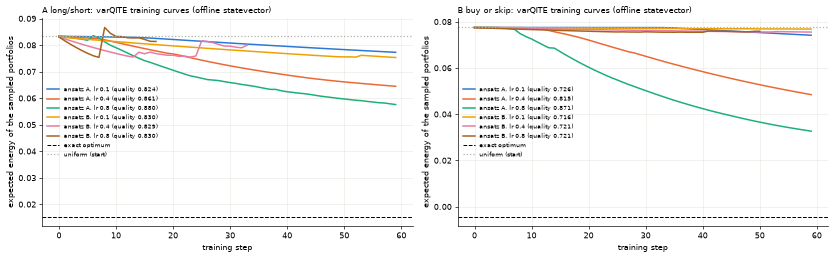

Text summary, A long/short: best varQITE run = ansatz A, lr 0.8: energy +0.08333 -> +0.05760 in 60 steps (7980 simulated circuits); quality 0.880, P(opt)/shot 0.0000, within 1 % 0.0004; circuit: 66 two-qubit gates, depth 33. NumPy vs Qiskit 9.7e-17. varQITE: IonQ and ORNL, arXiv 2404.16135 (implemented from the method description; no code reused).
  note: ansatz B at theta = 0 is a stationary point (all parameter-shift derivatives are 0), so it starts from small random angles.
Text summary, B buy or skip: best varQITE run = ansatz A, lr 0.8: energy +0.07754 -> +0.03267 in 60 steps (7980 simulated circuits); quality 0.871, P(opt)/shot 0.0000, within 1 % 0.0001; circuit: 66 two-qubit gates, depth 33. NumPy vs Qiskit 7.6e-17. varQITE: IonQ and ORNL, arXiv 2404.16135 (implemented from the method description; no code reused).
  note: ansatz B at theta = 0 is a stationary point (all parameter-shift derivatives are 0), so it starts from small random angles.


In [13]:
# varQITE (Pauli-term update rule): energy per training step, every run
fig, axes = plt.subplots(1, 2, figsize=(14, 4.4))
for ax, m in zip(axes, MODES):
    v = R["extras"][KEY[m]].get("varqite_pauli", {})
    e_min = R["models"][KEY[m]]["baselines"]["exact"]["e_min"]
    if v.get("status") != "completed":
        ax.set_title(f"{MODE_NAME[m]}: varQITE {v.get('status')}", loc="left")
        continue
    for run, color in zip(v["runs"], [BLUE, ORANGE, TEAL, YELLOW, PINK, BROWN, GREY, "#4a3aa7"]):
        ax.plot(run["energy_per_step"], color=color, linewidth=1.8, label=f"ansatz {run['kind']}, lr {run['lr']} (quality {run['metrics']['quality']:.3f})")
    ax.axhline(e_min, color="black", linestyle="--", linewidth=1.2, label="exact optimum")
    ax.axhline(R["models"][KEY[m]]["baselines"]["p0_control_uniform"]["model_expectation"], color=GREY, linestyle=":", linewidth=1.5, label="uniform (start)")
    ax.set_xlabel("training step")
    ax.set_ylabel("expected energy of the sampled portfolios")
    ax.set_title(f"{MODE_NAME[m]}: varQITE training curves (offline statevector)", loc="left", fontsize=10)
    ax.grid(True, color="#e5e4df", linewidth=0.6)
    ax.spines[["top", "right"]].set_visible(False)
    ax.legend(frameon=False, fontsize=7)
fig.tight_layout()
plt.show()
for m in MODES:
    v = R["extras"][KEY[m]].get("varqite_pauli", {})
    if v.get("status") == "completed":
        b = v["best"]
        print(f"Text summary, {MODE_NAME[m]}: best varQITE run = ansatz {b['kind']}, lr {b['lr']}: energy {b['energy_per_step'][0]:+.5f} -> {b['best_energy']:+.5f} "
              f"in {b['steps_run']} steps ({b['evaluations']} simulated circuits); quality {b['metrics']['quality']:.3f}, P(opt)/shot {b['metrics']['p_optimum_per_shot']:.4f}, "
              f"within 1 % {b['metrics']['p_within_1pct']:.4f}; circuit: {v['circuit_metrics']['two_qubit_gates']} two-qubit gates, depth {v['circuit_metrics']['depth']}. "
              f"NumPy vs Qiskit {v['numpy_vs_qiskit_max_difference']:.1e}. {v['citation']}.")
        print("  note: ansatz B at theta = 0 is a stationary point (all parameter-shift derivatives are 0), so it starts from small random angles.")

**How to read this chart.** X axis: training step. Y axis: expected energy of the portfolios the circuit samples (lower = better); dashed black = the exact best portfolio, dotted grey = where every run starts (uniform). One line per ansatz and learning rate. **Conclusion:** the energy falls steadily but slowly; even the best run stays well above the exact optimum and below LR-QAOA in quality at this budget, while using the same number of two-qubit gates as one QAOA layer. Trained on a noiseless local simulator; only the final circuit would be sampled on the IonQ noise model.

*Numbers quoted here are from the saved run; the printed summaries recompute them from the results file.*

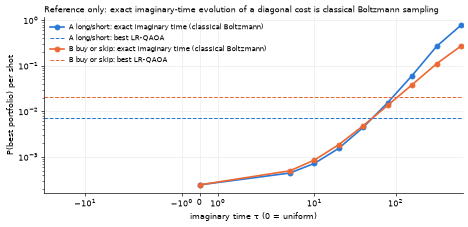

Text summary, A long/short: the classical Boltzmann curve passes the best LR-QAOA value at tau = 80.0; this curve is a classical calculation, not a quantum result.
Text summary, B buy or skip: the classical Boltzmann curve passes the best LR-QAOA value at tau = 160.0; this curve is a classical calculation, not a quantum result.


In [14]:
# exact imaginary-time evolution = classical Boltzmann reference curve
fig, ax = plt.subplots(figsize=(9, 3.8))
for m, color in zip(MODES, (BLUE, ORANGE)):
    curve = R["extras"][KEY[m]]["boltzmann_reference"]["curve"]
    ax.plot([c["tau"] for c in curve], [c["p_optimum_per_shot"] for c in curve], marker="o", color=color, linewidth=2, label=f"{MODE_NAME[m]}: exact imaginary time (classical Boltzmann)")
    best = max(R["models"][KEY[m]]["lr"].values(), key=lambda e: e["best"]["p_optimum_per_shot"])["best"]["p_optimum_per_shot"]
    ax.axhline(best, color=color, linestyle="--", linewidth=1.2, label=f"{MODE_NAME[m]}: best LR-QAOA")
ax.set_xscale("symlog", linthresh=5)
ax.set_yscale("log")
ax.set_xlabel("imaginary time τ (0 = uniform)")
ax.set_ylabel("P(best portfolio) per shot")
ax.set_title("Reference only: exact imaginary-time evolution of a diagonal cost is classical Boltzmann sampling", loc="left", fontsize=10)
ax.grid(True, color="#e5e4df", linewidth=0.6)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, fontsize=8)
plt.show()
for m in MODES:
    curve = R["extras"][KEY[m]]["boltzmann_reference"]["curve"]
    first = next((c["tau"] for c in curve if c["p_optimum_per_shot"] > max(e["best"]["p_optimum_per_shot"] for e in R["models"][KEY[m]]["lr"].values())), None)
    print(f"Text summary, {MODE_NAME[m]}: the classical Boltzmann curve passes the best LR-QAOA value at tau = {first}; "
          "this curve is a classical calculation, not a quantum result.")

## 11. Selected parameters for the next task, and the run report

The next task runs a **fixed** batch on Qollab: the p = 0 control plus the circuits below, one `backend.run` call, no tuning on the backend.

In [15]:
for m in MODES:
    sel = PARAMS["modes"][m]
    print(f"{MODE_NAME[m]} (eta {sel['eta']}, scale {sel['scale']:.4g}): exact optimum {sel['exact_optimum']['e_min']:+.5f}, "
          f"portfolio {sel['exact_optimum']['assignment']}")
    for p, e in sel["linear_ramp"].items():
        print(f"  LR-QAOA p={p}: (dgamma, dbeta) = ({e['best_dgamma']}, {e['best_dbeta']}), quality {e['quality']:.3f}, P(opt)/shot {e['p_optimum_per_shot']:.4f}")
    for p, e in sel["free_angles_best"].items():
        print(f"  free angles p={p}: gammas {np.round(e['gammas'], 3).tolist()}, betas {np.round(e['betas'], 3).tolist()} "
              f"({e['optimizer']} from {e['start']}, {e['evaluations']} evaluations), quality {e['quality']:.3f}, P(opt)/shot {e['p_optimum_per_shot']:.4f}")
print("transfer rule for larger sizes:", PARAMS["transfer_rule_larger_sizes"])
print()
task4_exit = task4_report.print_report(R)

A long/short (eta 1.0, scale 0.01508): exact optimum +0.01535, portfolio {'long': ['AAPL', 'GLD', 'JPM', 'TLT', 'PG', 'XLU', 'MSFT', 'SLV'], 'short': ['XOM', 'JNJ', 'VNQ', 'FCX']}
  LR-QAOA p=1: (dgamma, dbeta) = (0.3, -0.3), quality 0.895, P(opt)/shot 0.0011
  LR-QAOA p=2: (dgamma, dbeta) = (0.5, -0.3), quality 0.916, P(opt)/shot 0.0020
  LR-QAOA p=3: (dgamma, dbeta) = (0.7, -0.4), quality 0.931, P(opt)/shot 0.0044
  LR-QAOA p=4: (dgamma, dbeta) = (0.7, -0.4), quality 0.943, P(opt)/shot 0.0058
  LR-QAOA p=5: (dgamma, dbeta) = (0.7, -0.4), quality 0.950, P(opt)/shot 0.0073
  free angles p=1: gammas [0.304], betas [-0.269] (L-BFGS-B from lr_tuned, 24 evaluations), quality 0.897, P(opt)/shot 0.0010
  free angles p=2: gammas [0.224, 0.632], betas [-0.339, -0.164] (L-BFGS-B from lr_tuned, 65 evaluations), quality 0.919, P(opt)/shot 0.0023
  free angles p=3: gammas [0.213, 0.455, 0.609], betas [-0.418, -0.234, -0.153] (L-BFGS-B from lr_tuned, 98 evaluations), quality 0.935, P(opt)/shot 0.00

- Tests (python -m unittest discover -s tests -t .): 118 passed, 0 failed, 0 skipped
RESULT: PASS
